# Power control without channel knowledge

> Codebook tokens over BPSK with channel inversion, when the transmitter must predict the channel: from its history, or from a map and where the nodes reported being.

Agents on a 9 × 9 grid send each other a 7 × 7 map of codebook tokens at every step: 49 indices into a codebook of
256, so 392 bits. The link is the communication model of C3-WM:

* **Modulation:** the bits go out as BPSK. The channel coefficient stays the same during a message (block fading),
  plus AWGN.
* **Detection:** coherent maximum-likelihood, `Re(h* y) ≥ 0`. Bit errors are not corrected, so the receiver gets
  the tokens they produce.
* **Channel inversion:** the transmitter picks the power that reaches a target SNR `Γ`, `ρ = Γσ²/ĝ`, for a
  predicted gain `ĝ`. It sends only if `ρ ≤ ρ_max`.

The transmitter does not know the current gain `|h_t|²`, so it predicts it. The predictors compared here:

| predictor | what the transmitter uses | comm-core |
|---|---|---|
| last gain | the link's gain at the last step | `PredictedChannelInversion` with `past[0]` |
| linear on `\|h\|²` | the last 4 gains, least squares on `\|h\|²` (C3-WM's eq. 24) | `fit_gain_predictor(..., domain='linear')` |
| linear in dB | the last 4 gains, least squares in dB | `fit_gain_predictor(..., domain='db')` |
| map, receiver's last cell | a ray-traced map, its own cell, the receiver's last reported cell | `MapChannelInversion` |
| map, robust | the same, plus the receiver's reported heading: the weakest cell it can have reached | `MapChannelInversion(reachable=...)` |
| perfect CSI | the current gain (the ideal) | `ChannelInversion` |

**Comparing them fairly.** The transmitter's job (C3-WM's eq. 14) is to reach the target SNR with as little power
as possible. A predictor that underestimates gains reaches the target more often, but spends more power. So each
predictor is run with a margin `m` (`ρ = Γσ²·m/ĝ`), swept. It is judged by the mean power it needs, relative to
perfect CSI's, to reach the target on 90%, 95% or 99% of the transmissions that perfect CSI can serve within
`ρ_max`. Links it misses count as failures, and power spent on links that cannot be served counts as cost.

(Counting lost tokens within a fixed power budget would judge something else: under a total budget, abandoning weak
links and favouring strong ones loses fewer tokens than reaching the target on every link. That metric mixes the
quality of the prediction with the choice of policy.)

In [ ]:
import math

import matplotlib.pyplot as plt
import numpy as np

from comm_core import *

## The channel map

The channel between every pair of grid cells, as a ray tracer gives it. Here it's a room with a line-of-sight path
and a reflection off each of the 4 walls, at 2.4 GHz. With Sionna RT, use `paths.cfr(..., normalize=False)` and
`RayTracedFading.from_files`.

In [ ]:
C, F = 299_792_458.0, 2.4e9
SIZE, HEIGHT = 9, 0.5
cells = [(x, y) for x in range(SIZE) for y in range(SIZE)]
WALLS = [(0, -0.5, -0.6), (0, SIZE - 0.5, -0.6), (1, -0.5, -0.5), (1, SIZE - 0.5, -0.5)]   # (axis, coordinate, reflection)

def channel(tx, rx):
    "Line of sight + one reflection off each wall (image method)."
    tx, rx = np.array([*tx, HEIGHT]), np.array([*rx, HEIGHT])
    h = 0j
    for source, gain in [(tx, 1.0)] + [(tx * np.where(np.arange(3) == a, -1, 1) + 2 * c * (np.arange(3) == a), g) for a, c, g in WALLS]:
        L = np.linalg.norm(rx - source)
        h += gain * C / F / (4 * np.pi * L) * np.exp(-2j * np.pi * F * L / C)
    return h

H = np.array([[channel(tx, rx) if tx != rx else 0 for tx in cells] for rx in cells])   # H[rx, tx]
fading = RayTracedFading(H, cells)
print(f'{len(cells)} cells; path gain between cells: {10 * np.log10(np.abs(H[H != 0]) ** 2).min():.0f} to '
      f'{10 * np.log10(np.abs(H[H != 0]) ** 2).max():.0f} dB')

81 cells; path gain between cells: -91 to -39 dB


## The agents

As in MultiGrid, each agent has a heading, and at each step it stays, turns left or right, or moves one cell
forward if it can. The application moves the agents and tells the channel where they are; comm-core never moves
anything.

In [ ]:
AGENTS = ['agent_0', 'agent_1', 'agent_2']
STEPS, HISTORY = 50, 4
DIRS = [(1, 0), (0, 1), (-1, 0), (0, -1)]

def walks(seed):
    "One episode: per step, every agent's cell and heading."
    rng = np.random.default_rng(seed)
    start = rng.choice(SIZE * SIZE, len(AGENTS), replace=False)                # distinct cells
    pos = {a: (int(k) // SIZE, int(k) % SIZE) for a, k in zip(AGENTS, start)}
    head = {a: int(rng.integers(4)) for a in AGENTS}
    out = []
    for _ in range(STEPS):
        out.append((dict(pos), dict(head)))
        for a in AGENTS:
            action = rng.integers(4)                                     # stay, left, right, forward
            if action == 1: head[a] = (head[a] - 1) % 4
            if action == 2: head[a] = (head[a] + 1) % 4
            if action == 3:
                nxt = (pos[a][0] + DIRS[head[a]][0], pos[a][1] + DIRS[head[a]][1])
                if 0 <= nxt[0] < SIZE and 0 <= nxt[1] < SIZE and nxt not in [pos[b] for b in AGENTS if b != a]:
                    pos[a] = nxt
    return out

def reachable(cell, heading):
    "Where an agent that reported `cell` and `heading` can be one step later: there, or one cell ahead."
    return [cell, (cell[0] + DIRS[heading][0], cell[1] + DIRS[heading][1])]

## Fitting the history predictors

The training set (C3-WM's D_channel) holds the gain of every directed link at every step of recorded episodes.
`gain_windows` turns it into (last 4 gains → next gain) pairs, and `fit_gain_predictor` fits the linear predictors.
The map predictors need no training.

In [ ]:
gain = lambda tx, rx: fading.gain_between(tx, rx)
LINKS = [(s, r) for s in AGENTS for r in AGENTS if s != r]

def link_gains(episode):
    return {(s, r): [gain(pos[s], pos[r]) for pos, _ in episode] for s, r in LINKS}

training = [g for seed in range(300) for g in link_gains(walks(seed)).values()]
psi_lin = fit_gain_predictor(training, history=HISTORY)                   # C3-WM's eq. 24
psi_db = fit_gain_predictor(training, history=HISTORY, domain='db')

## The comparison

On test episodes, each predictor's estimate is computed for every directed link at every step, from what the
transmitter would know then. For any margin, the power, whether it is sent, and whether the SNR reaches the target
then follow directly.

In [ ]:
db = lambda g: 10 * np.log10(np.maximum(g, 1e-30))
erfc = np.vectorize(math.erfc)
SNR_TARGET, NOISE_W, MAX_POWER_W = 10 ** 0.7, 10 ** ((-94 - 30) / 10), 2e-5          # Γ = 7 dB, σ² = -94 dBm, ρ_max = 20 µW
estimates = {k: [] for k in ('last gain', 'linear on |h|²', 'linear in dB', "map, receiver's last cell", 'map, robust', 'perfect CSI')}
truth = []
for seed in range(10_000, 10_040):
    episode = walks(seed)
    for s, r in LINKS:
        g = [gain(pos[s], pos[r]) for pos, _ in episode]
        for t in range(HISTORY, STEPS):
            past = np.array(g[t - HISTORY:t][::-1])                       # most recent first
            (pos, _), (pos_before, head_before) = episode[t], episode[t - 1]
            truth.append(g[t])
            estimates['last gain'].append(past[0])
            estimates['linear on |h|²'].append(max(psi_lin(past), 0.0))
            estimates['linear in dB'].append(psi_db(past))
            estimates["map, receiver's last cell"].append(gain(pos[s], pos_before[r]))
            near = [c for c in reachable(pos_before[r], head_before[r]) if c in fading.index]
            estimates['map, robust'].append(min(gain(pos[s], c) for c in ([c for c in near if c != pos[s]] or near)))
            estimates['perfect CSI'].append(g[t])
truth = np.array(truth)
estimates = {k: np.array(v) for k, v in estimates.items()}

servable = SNR_TARGET * NOISE_W / truth <= MAX_POWER_W            # perfect CSI can serve these
perfect_power = np.where(servable, SNR_TARGET * NOISE_W / truth, 0.0).mean()

def outcome(estimate, margin_db):
    "(share of the servable transmissions reaching the target, mean power relative to perfect CSI's) at a margin."
    power = SNR_TARGET * NOISE_W * 10 ** (margin_db / 10) / np.maximum(estimate, 1e-30)
    sent = power <= MAX_POWER_W
    reached = sent & (power * truth / NOISE_W >= SNR_TARGET * (1 - 1e-9))
    return reached[servable].mean(), np.where(sent, power, 0.0).mean() / perfect_power

margins = np.arange(-6, 30.01, 0.1)
curves = {k: np.array([outcome(e, m) for m in margins]) for k, e in estimates.items()}

def power_for(k, share):
    "Least relative power at which predictor k reaches the target on `share` of the servable transmissions."
    ok = curves[k][:, 0] >= share
    return curves[k][ok, 1].min() if ok.any() else np.inf

print(f"{'':26s} {'error (dB): mean':>16s} {'spread':>7s} | power to reach Γ on 90 / 95 / 99% (× perfect CSI)")
for k, e in estimates.items():
    err = db(e) - db(truth)
    err = err[np.isfinite(err)]                                    # same cell: no error to measure
    print(f'{k:26s} {err.mean():+16.1f} {err.std():7.1f} | ' +
          '  '.join(f'{power_for(k, q):5.1f}' if np.isfinite(power_for(k, q)) else '  -  ' for q in (0.9, 0.95, 0.99)))


                           error (dB): mean  spread | power to reach Γ on 90 / 95 / 99% (× perfect CSI)
last gain                              -0.0     4.1 |   1.9    -      -  
linear on |h|²                         +1.8     4.4 |   1.4    2.7    -  
linear in dB                           +0.0     3.9 |   1.5    -      -  
map, receiver's last cell              -0.0     3.0 |   1.0    -      -  
map, robust                            -2.1     3.7 |   1.4    1.4    1.4
perfect CSI                            +0.0     0.0 |   1.0    1.0    1.0


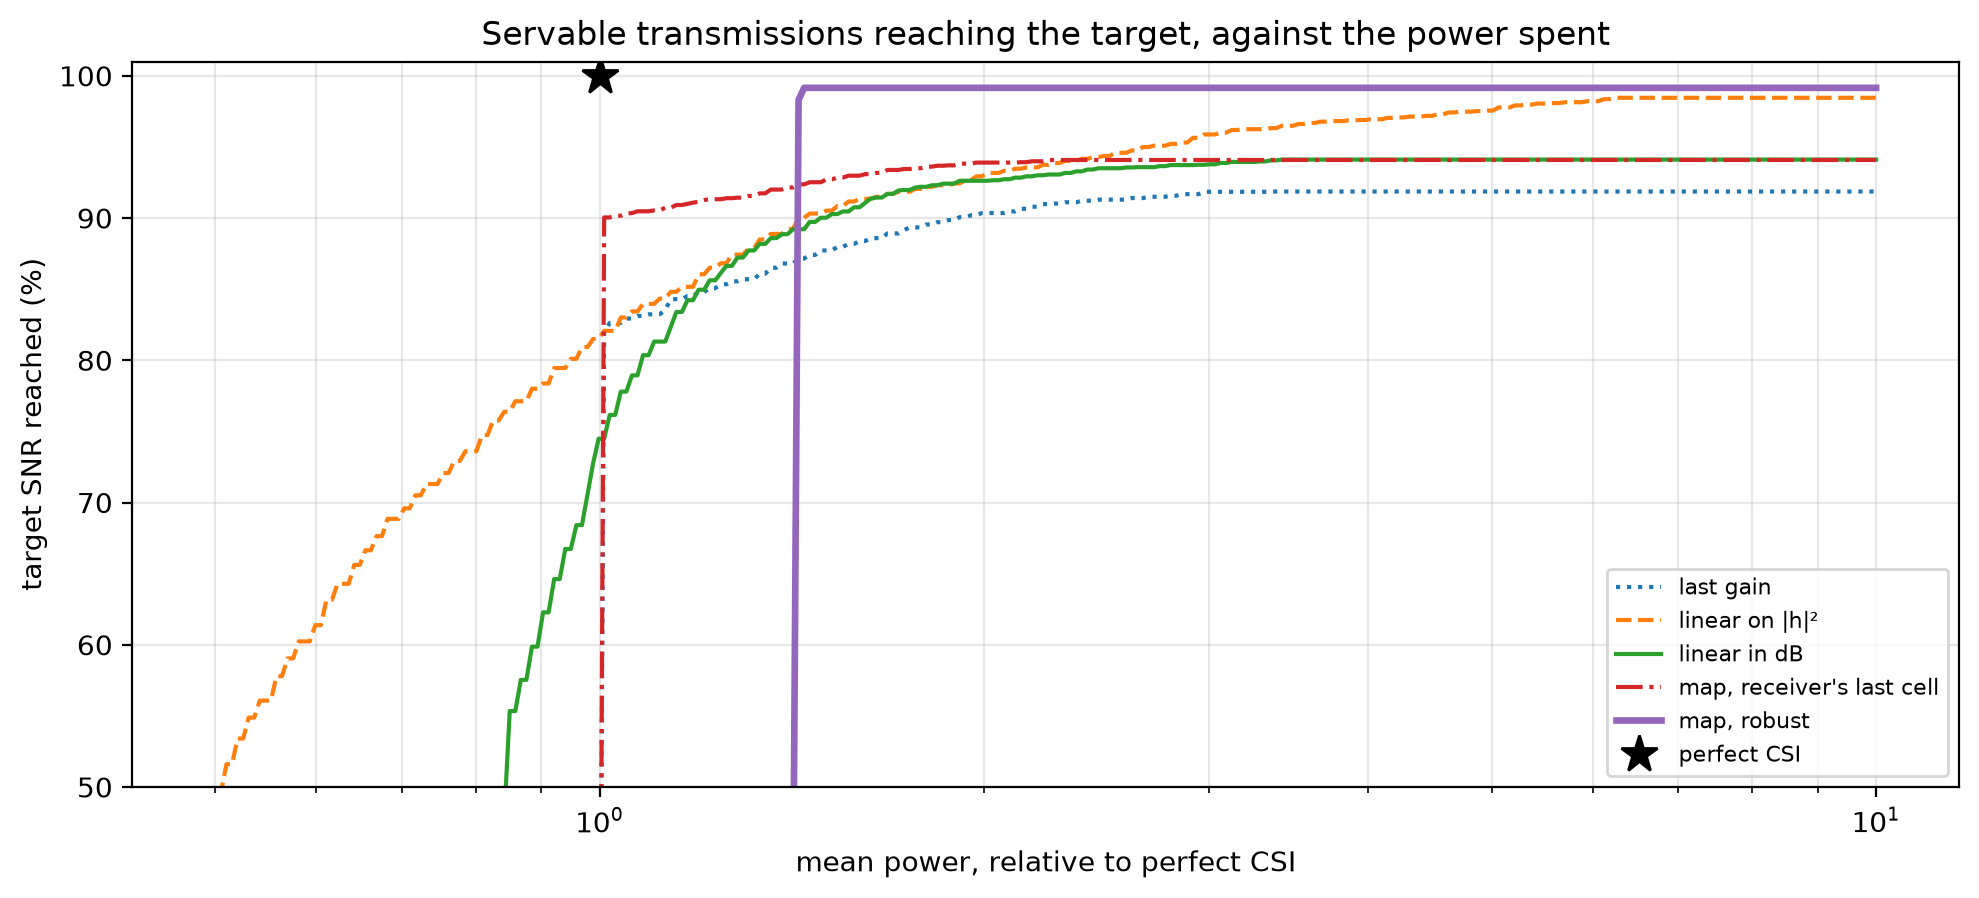

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.6))
style = {'last gain': ':', 'linear on |h|²': '--', 'linear in dB': '-', "map, receiver's last cell": '-.', 'map, robust': '-'}
powers = np.geomspace(0.5, 10, 300)
for k, ls in style.items():
    best = [curves[k][curves[k][:, 1] <= p, 0].max() if (curves[k][:, 1] <= p).any() else np.nan for p in powers]
    ax.plot(powers, 100 * np.array(best), ls, lw=2.4 if k == 'map, robust' else 1.5, label=k)
ax.plot(1, 100, 'k*', ms=14, label='perfect CSI')
ax.set(xscale='log', ylim=(50, 101), xlabel='mean power, relative to perfect CSI', ylabel='target SNR reached (%)',
       title='Servable transmissions reaching the target, against the power spent')
ax.grid(alpha=0.3, which='both'); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()

## The same through a network

The analysis above, checked by running comm-core's power controls for real, one operating point each. Each
predictor runs with the margin at which it reaches the target on 90% of the servable transmissions, with the least
power, through a `LinkLevelChannel`: every bit, with the gain histories and position reports kept by the power
controls themselves.

In [ ]:
def margin_at(k, share=0.9):
    "The margin at which predictor k reaches the target on `share` of the servable transmissions with the least power."
    ok = curves[k][:, 0] >= share
    return margins[ok][np.argmin(curves[k][ok, 1])]

margin_for = {k: margin_at(k) for k in style}
margin_for['perfect CSI'] = 0.0
heads = {}

def power_control(name, m):
    if name == 'perfect CSI':
        return ChannelInversion(7.0, max_power=MAX_POWER_W)
    if name.startswith('map'):
        return MapChannelInversion(fading, reachable=reachable if name == 'map, robust' else None, states=lambda: heads,
                                   target_snr_db=7.0, max_power=MAX_POWER_W, margin_db=m, fallback=FixedPower(MAX_POWER_W / 2))
    predictor = {'last gain': lambda past: past[0], 'linear on |h|²': psi_lin, 'linear in dB': psi_db}[name]
    return PredictedChannelInversion(predictor, 1 if name == 'last gain' else HISTORY, 7.0, MAX_POWER_W,
                                     fallback_power=MAX_POWER_W / 2, margin_db=m)

def simulate(name, episodes=range(10_000, 10_040)):
    radio = LinkLevelChannel(codec=IndexCodec(256), modulation=BPSK(), fading=fading,
                             power_control=power_control(name, margin_for[name]), noise_power=NOISE_W)
    net = Network([Node(a) for a in AGENTS], FullMeshTopology(AGENTS), IdealProtocol(), AnalyticalBackend(radio))
    rng = np.random.default_rng(0)
    reached, power = [], []
    for seed in episodes:
        episode = walks(seed)
        net.reset(seed)
        for t, (pos, head) in enumerate(episode):
            radio.set_positions(pos)
            heads.clear(); heads.update(head)
            tokens = {a: rng.integers(0, 256, 49) for a in AGENTS}
            for s, r in LINKS:
                net.send(Message(s, r, payload=tokens[s], type='tokens'))
            for res in net.step():
                if t < HISTORY or math.isinf(res.snr_db):          # as in the analysis: from step 4 on
                    continue
                g = 10 ** (res.metadata['channel_gain_db'] / 10)
                power.append(res.metadata['tx_power'])
                if SNR_TARGET * NOISE_W / g <= MAX_POWER_W:                    # servable
                    reached.append(res.success and res.snr_db >= 7.0 - 1e-9)
    return np.mean(reached), np.mean(power) / perfect_power

print(f"{'':26s} {'margin':>8s} {'simulated: reached':>19s} {'power':>6s} | {'analysis: reached':>18s} {'power':>6s}")
for name in list(style) + ['perfect CSI']:
    sim_reached, sim_power = simulate(name)
    ana_reached, ana_power = outcome(estimates[name], margin_for[name])
    print(f'{name:26s} {margin_for[name]:+6.1f}dB {100 * sim_reached:18.1f}% {sim_power:5.2f}x | {100 * ana_reached:17.1f}% {ana_power:5.2f}x')

                             margin  simulated: reached  power |  analysis: reached  power
last gain                    +3.9dB               90.1%  1.91x |              90.1%  1.91x
linear on |h|²               +5.4dB               90.0%  1.42x |              90.0%  1.42x
linear in dB                 +3.1dB               90.0%  1.48x |              90.0%  1.48x
map, receiver's last cell    -0.0dB               90.1%  1.00x |              90.0%  1.00x
map, robust                  +0.5dB               98.3%  1.43x |              98.3%  1.43x
perfect CSI                  +0.0dB              100.0%  1.00x |             100.0%  1.00x


* **History alone can't make the target reliable.** Last step's gain, a linear fit on `|h|²` (C3-WM's) or in dB:
  each reaches the target 90% of the time with a margin, but not 95% or 99% within the power budget. Their errors
  have too wide a spread (several dB) for any margin to cover. Agents move a whole cell, many wavelengths, between
  steps, so a link's past says little about its next gain.
* **Fitted on `|h|²`,** the predictor is biased (it overestimates weak links) and needs a large margin. In dB, it is
  unbiased and needs less.
* **The map gives the transmitter what the history lacks.** The receiver's last reported cell alone predicts with
  less spread. With its reported heading as well, the robust lookup takes the weakest cell the receiver can have
  reached. It never overestimates, so it reaches the target on nearly every servable transmission, at a fixed
  extra power over perfect CSI.
* **The cost** is a few bits of position and heading in each message, and a ray-traced map of the area, which
  C3-WM computes anyway.
* **Through a network** (`MapChannelInversion`, `PredictedChannelInversion`), the simulation agrees with the
  analysis. Small differences come from the first steps of each episode, where the power controls fall back to a
  fixed power.

In [ ]:
assert np.isfinite(power_for('map, robust', 0.99))
assert all(power_for(k, 0.99) == np.inf for k in ('last gain', 'linear on |h|²', 'linear in dB'))
assert power_for('map, robust', 0.95) < min(power_for(k, 0.95) for k in ('last gain', 'linear on |h|²', 'linear in dB'))